# Lab 5: Exploratory Data Analysis with Pandas, Matplotlib and Seaborn

In [1]:
import os, json, warnings
warnings.filterwarnings('ignore')
os.makedirs('figs', exist_ok=True)
os.makedirs('results', exist_ok=True)

def save_result(name, value):
    path = 'results/results.json'
    data = json.load(open(path)) if os.path.exists(path) else {}
    data[name] = value
    json.dump(data, open(path, 'w'), indent=2, default=str)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')
%matplotlib inline
df = pd.read_csv('dataset_part_2.csv')
df.head()

,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


### Flight number vs. payload mass, coloured by landing outcome

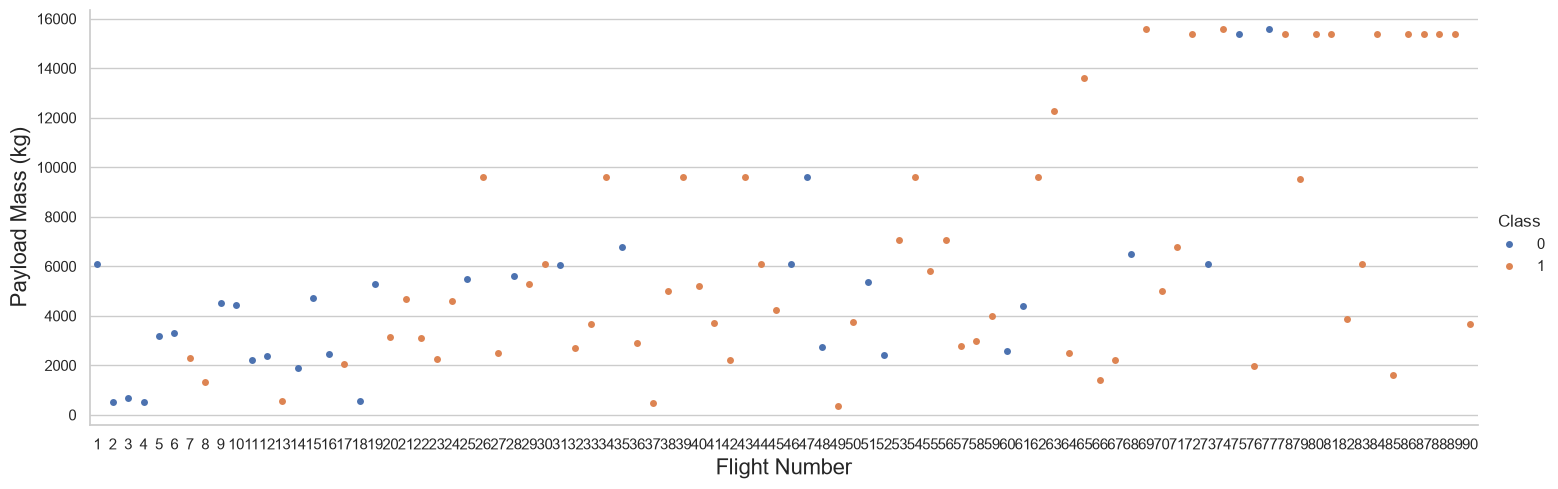

In [2]:
sns.catplot(y='PayloadMass', x='FlightNumber', hue='Class', data=df, aspect=3)
plt.xlabel('Flight Number', fontsize=16)
plt.ylabel('Payload Mass (kg)', fontsize=16)
plt.savefig('figs/flight_vs_payload.png', dpi=120, bbox_inches='tight')
plt.show()

### Task 1: Flight number vs. launch site

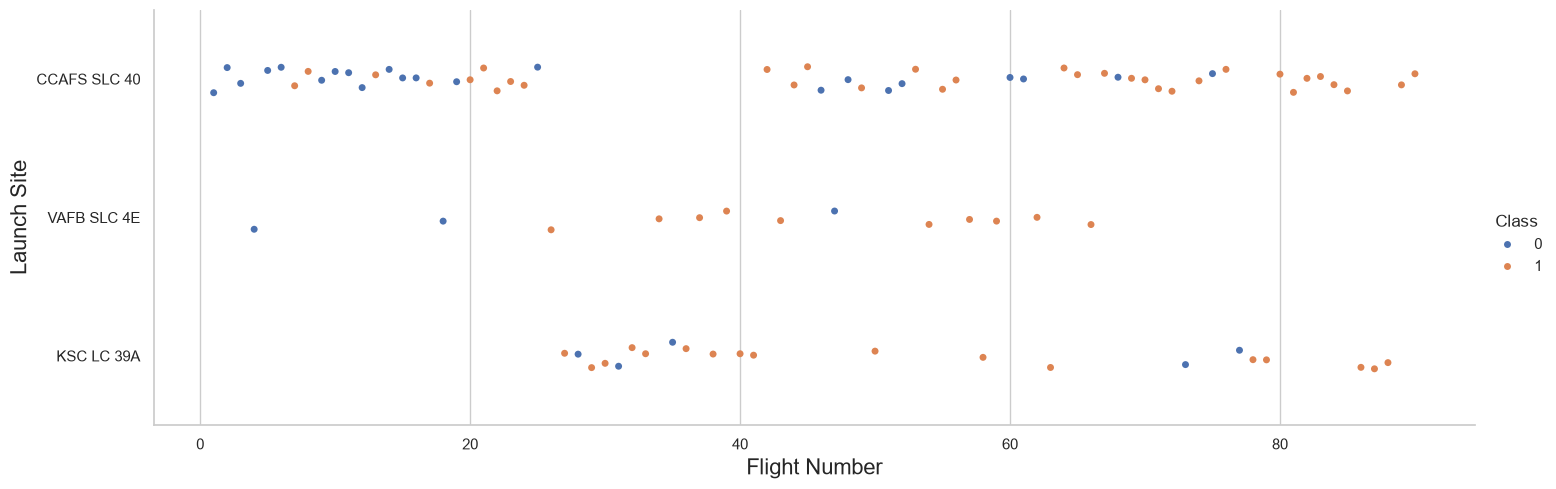

In [3]:
sns.catplot(y='LaunchSite', x='FlightNumber', hue='Class', data=df, aspect=3)
plt.xlabel('Flight Number', fontsize=16)
plt.ylabel('Launch Site', fontsize=16)
plt.savefig('figs/flight_vs_site.png', dpi=120, bbox_inches='tight')
plt.show()

### Task 2: Payload mass vs. launch site

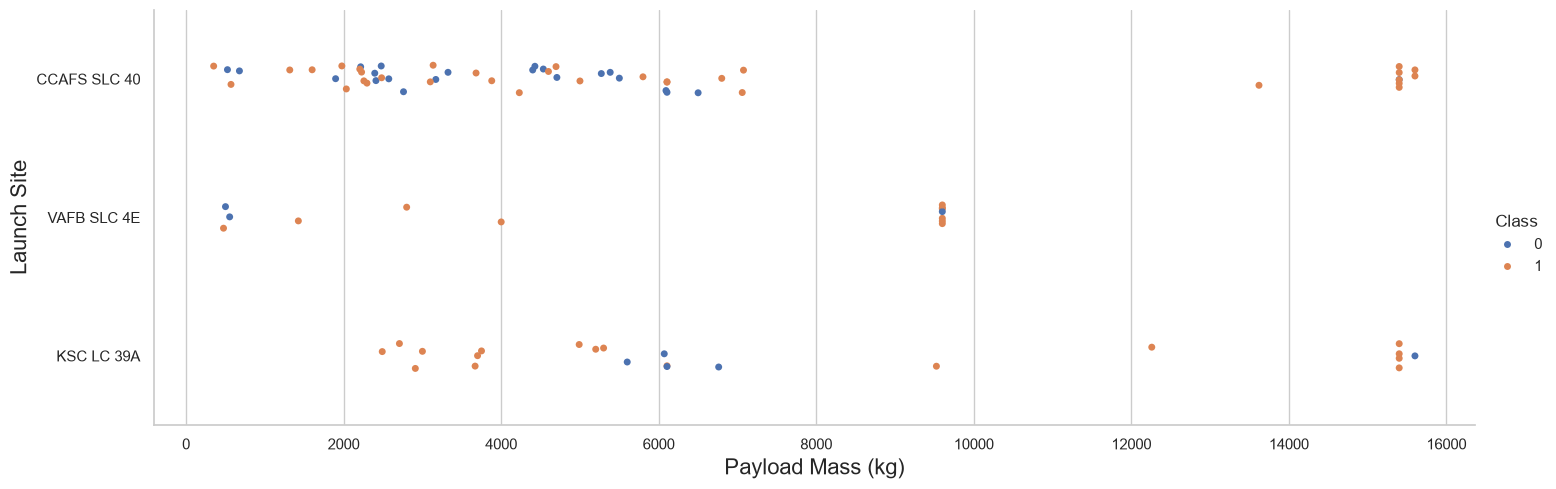

In [4]:
sns.catplot(y='LaunchSite', x='PayloadMass', hue='Class', data=df, aspect=3)
plt.xlabel('Payload Mass (kg)', fontsize=16)
plt.ylabel('Launch Site', fontsize=16)
plt.savefig('figs/payload_vs_site.png', dpi=120, bbox_inches='tight')
plt.show()

### Task 3: Success rate of each orbit type

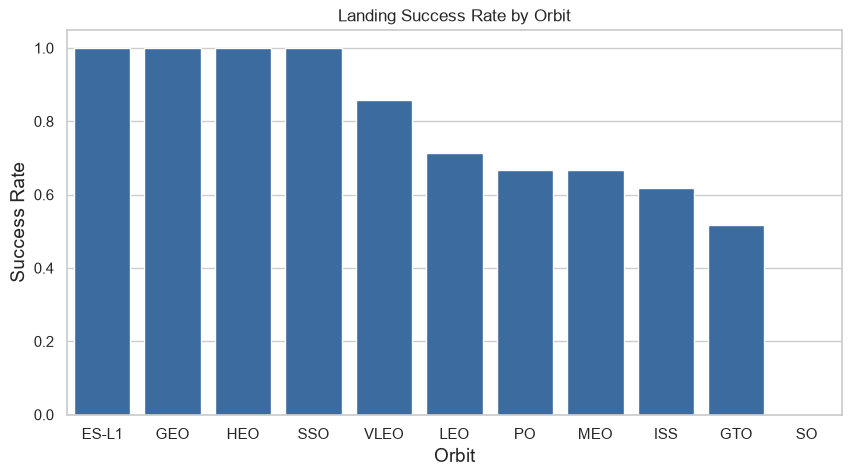

In [5]:
orbit_rate = df.groupby('Orbit')['Class'].mean().sort_values(ascending=False)
save_result('orbit_success_rate', orbit_rate.round(3).to_dict())
plt.figure(figsize=(10, 5))
sns.barplot(x=orbit_rate.index, y=orbit_rate.values, color='#2b6cb0')
plt.xlabel('Orbit', fontsize=14)
plt.ylabel('Success Rate', fontsize=14)
plt.title('Landing Success Rate by Orbit')
plt.savefig('figs/orbit_success.png', dpi=120, bbox_inches='tight')
plt.show()

### Task 4: Flight number vs. orbit type

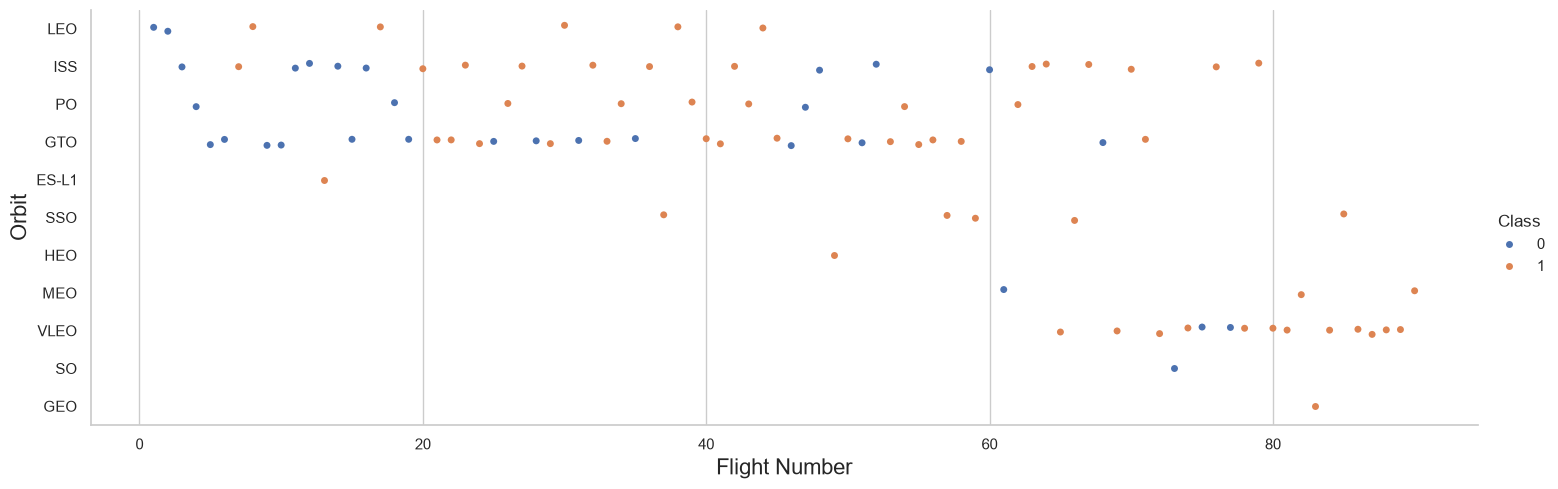

In [6]:
sns.catplot(y='Orbit', x='FlightNumber', hue='Class', data=df, aspect=3)
plt.xlabel('Flight Number', fontsize=16)
plt.ylabel('Orbit', fontsize=16)
plt.savefig('figs/flight_vs_orbit.png', dpi=120, bbox_inches='tight')
plt.show()

### Task 5: Payload mass vs. orbit type

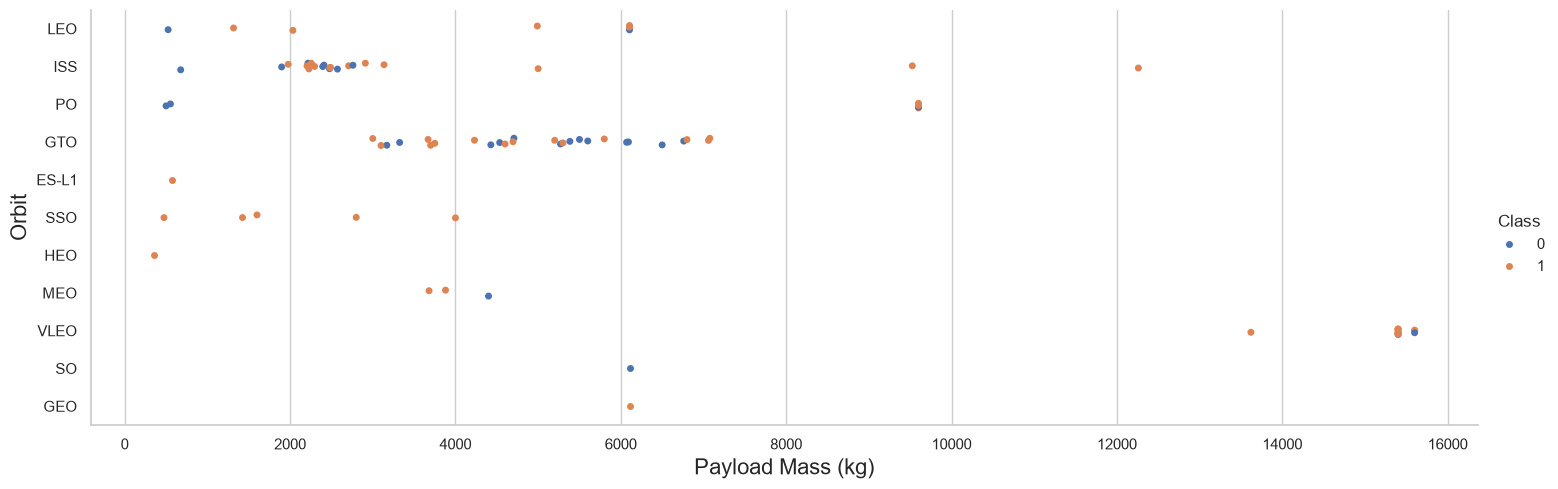

In [7]:
sns.catplot(y='Orbit', x='PayloadMass', hue='Class', data=df, aspect=3)
plt.xlabel('Payload Mass (kg)', fontsize=16)
plt.ylabel('Orbit', fontsize=16)
plt.savefig('figs/payload_vs_orbit.png', dpi=120, bbox_inches='tight')
plt.show()

### Task 6: Yearly launch success trend

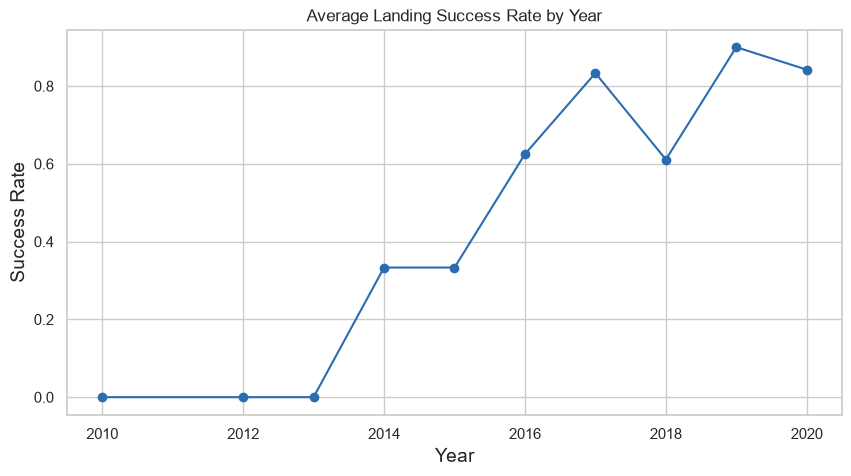

In [8]:
df['Year'] = pd.to_datetime(df['Date']).dt.year
yearly = df.groupby('Year')['Class'].mean()
save_result('yearly_success', yearly.round(3).to_dict())
plt.figure(figsize=(10, 5))
plt.plot(yearly.index, yearly.values, marker='o', color='#2b6cb0')
plt.xlabel('Year', fontsize=14)
plt.ylabel('Success Rate', fontsize=14)
plt.title('Average Landing Success Rate by Year')
plt.savefig('figs/yearly_trend.png', dpi=120, bbox_inches='tight')
plt.show()

## Extra insights beyond the lab
### Success by booster block and by booster reuse

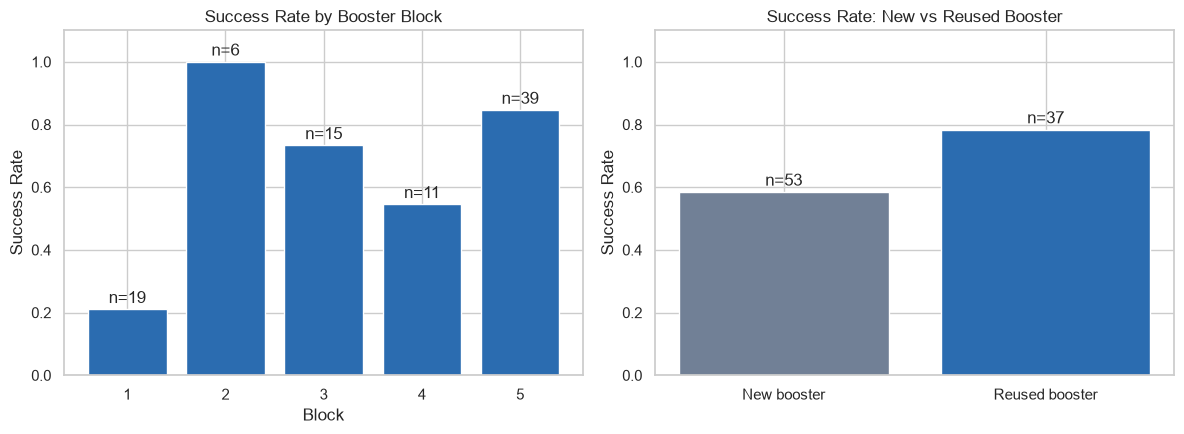

In [9]:
block_rate = df.groupby('Block')['Class'].agg(['mean', 'count'])
reuse_rate = df.groupby('Reused')['Class'].agg(['mean', 'count'])
grid_rate = df.groupby('GridFins')['Class'].agg(['mean', 'count'])
legs_rate = df.groupby('Legs')['Class'].agg(['mean', 'count'])
save_result('block_success', block_rate['mean'].round(3).to_dict())
save_result('block_count', block_rate['count'].to_dict())
save_result('reused_success', reuse_rate['mean'].round(3).to_dict())
save_result('gridfins_success', grid_rate['mean'].round(3).to_dict())
save_result('legs_success', legs_rate['mean'].round(3).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(block_rate.index.astype(int).astype(str), block_rate['mean'], color='#2b6cb0')
axes[0].set_title('Success Rate by Booster Block'); axes[0].set_xlabel('Block'); axes[0].set_ylabel('Success Rate')
for i, (m, c) in enumerate(zip(block_rate['mean'], block_rate['count'])):
    axes[0].text(i, m + 0.02, f'n={c}', ha='center')
labels = ['New booster', 'Reused booster']
axes[1].bar(labels, reuse_rate['mean'], color=['#718096', '#2b6cb0'])
axes[1].set_title('Success Rate: New vs Reused Booster'); axes[1].set_ylabel('Success Rate')
for i, (m, c) in enumerate(zip(reuse_rate['mean'], reuse_rate['count'])):
    axes[1].text(i, m + 0.02, f'n={c}', ha='center')
for ax in axes: ax.set_ylim(0, 1.1)
plt.tight_layout()
plt.savefig('figs/block_reuse.png', dpi=120, bbox_inches='tight')
plt.show()

### Learning curve: rolling success rate over the last 10 flights

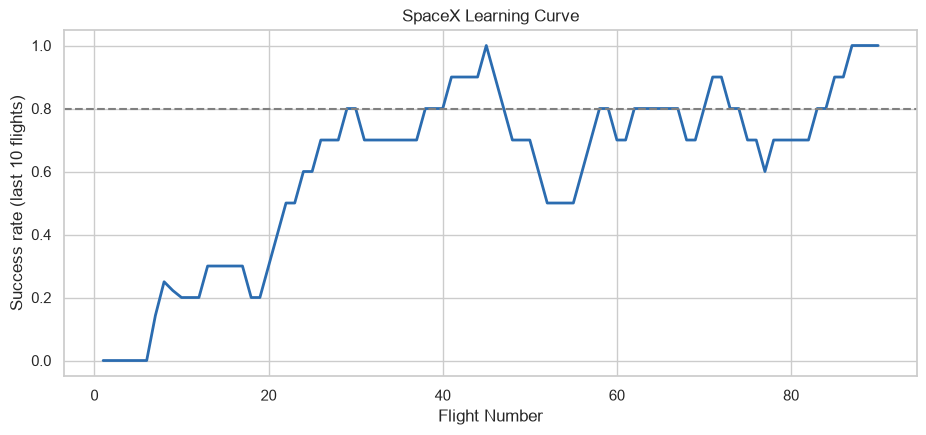

Rolling success first reaches 80% at flight 29


In [10]:
df['Rolling10'] = df['Class'].rolling(10, min_periods=1).mean()
first_streak = df.loc[df['Rolling10'] >= 0.8, 'FlightNumber'].min()
save_result('rolling80_first_flight', int(first_streak))
plt.figure(figsize=(11, 4.5))
plt.plot(df['FlightNumber'], df['Rolling10'], color='#2b6cb0', lw=2)
plt.axhline(0.8, ls='--', color='grey')
plt.xlabel('Flight Number'); plt.ylabel('Success rate (last 10 flights)')
plt.title('SpaceX Learning Curve')
plt.savefig('figs/learning_curve.png', dpi=120, bbox_inches='tight')
plt.show()
print('Rolling success first reaches 80% at flight', first_streak)

## Feature engineering
### Task 7: Create dummy variables for categorical columns

In [11]:
features = df[['FlightNumber', 'PayloadMass', 'Orbit', 'LaunchSite', 'Flights', 'GridFins', 'Reused', 'Legs',
               'LandingPad', 'Block', 'ReusedCount', 'Serial']]
features_one_hot = pd.get_dummies(features, columns=['Orbit', 'LaunchSite', 'LandingPad', 'Serial'])
save_result('one_hot_columns', int(features_one_hot.shape[1]))
features_one_hot.shape

(90, 80)

### Task 8: Cast all numeric columns to float64

In [12]:
features_one_hot = features_one_hot.astype('float64')
features_one_hot.to_csv('dataset_part_3.csv', index=False)
features_one_hot.head()

,FlightNumber,PayloadMass,Flights,GridFins,Reused,Legs,Block,ReusedCount,Orbit_ES-L1,Orbit_GEO,...,Serial_B1048,Serial_B1049,Serial_B1050,Serial_B1051,Serial_B1054,Serial_B1056,Serial_B1058,Serial_B1059,Serial_B1060,Serial_B1062
0,1.0,6104.959412,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2.0,525.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,3.0,677.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,4.0,500.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,5.0,3170.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
